# CASO DE ESTUDIO — CONSULTORÍA DE BIG DATA (2026-II)
## Auditoría Distribuida y Supervisión Algorítmica del Sistema Financiero de EE. UU.
**Universidad Externado de Colombia · Maestría en Ciencia de Datos**

* **Entidad Contratante:** Consumer Financial Protection Bureau (CFPB) – Washington, D.C.
* **Firma Consultora / Equipo Auditor:**
  * **Arnold Santiago Torres Anzola** — *(Componente A: Datos y Almacenamiento en HDFS)*
  * **Alejandro Esteban Martínez Acosta** — *(Componente B: Procesamiento Distribuido en Apache Spark)*
  * **Nicolas Felipe Figueroa Salgado** — *(Componente C: Desempeño, Spark UI, Visualizaciones y MLlib)*
  * *Componente D (Redacción, Informe Estratégico y Presentación): Responsabilidad Compartida.*
* **Docente Titular:** Yessica Liceth Velásquez Castiblanco
* **Mandato de la Consultoría:** Evaluar el cumplimiento de los tiempos legales de respuesta bancaria (SLA de 15 días), detectar productos financieros con riesgo sistémico o litigiosidad desmedida, auditar disparidades geográficas en la protección al consumidor y diseñar un modelo de supervisión predictiva con Machine Learning sobre un censo masivo de 15.017.091 quejas (~4,6 GB) en un clúster Apache Spark sobre Hadoop YARN y HDFS.

---


---
## MAPA DE EJECUCIONES DE LA CONSULTORÍA Y RESULTADOS CLAVE

Cada celda de este cuaderno responde a un **objetivo regulatorio y de negocio** para la CFPB, ejecutado sobre arquitectura distribuida:

| Bloque | Ejecución en el Clúster | Propósito en la Consultoría (CFPB) | Resultado e Impacto Observado |
| :---: | :--- | :--- | :--- |
| **Bloque 1** | **SparkSession sobre YARN** *(Comp. B)* | Dimensionar el clúster con concurrencia óptima para procesar el censo nacional sin cuellos de botella. | 2 ejecutores, 4 cores físicos, 8 GB RAM, 200 particiones de shuffle y Adaptive Query Execution (AQE) activo. |
| **Bloque 2** | **Ingesta HDFS con StructType** *(Comp. A)* | Cargar el repositorio histórico masivo (4,6 GB) con alta fidelidad de tipos y tolerancia a fallos. | Ingesta en **1,24 s** dividida en **35 bloques de 128 MB** con **factor de replicación 2.0** (70 réplicas físicas entre DataNodes). |
| **Bloque 3** | **Auditoría Censal (EDA)** *(Comp. B)* | Auditar el 100% de las quejas ciudadanas (sin muestreo) y calcular la latencia de respuesta institucional. | **15.017.091 registros** auditados; 18 atributos; integridad del 100%; latencia promedio de respuesta de **4,45 días**. |
| **Bloque 4** | **Transformación 1: Riesgo por Producto** *(Comp. B)* | Identificar qué productos concentran disputas y cuáles otorgan compensación económica al consumidor. | 14 categorías en **13,75 s**. Hallazgo: *Credit reporting* concentra >65% de quejas pero con <10% de compensación económica. |
| **Bloque 4** | **Transformación 2: Equidad Regional** *(Comp. B)* | Evaluar disparidades territoriales de atención al cliente cruzando 51 estados con la macro-región. | 69 combinaciones en **12,44 s**. Hallazgo: La región **Sur concentra el 40,3%** de la litigiosidad del país. |
| **Bloque 5** | **Optimización Catalyst y AQE** *(Comp. B)* | Auditar la eficiencia computacional del plan físico para no saturar la red ni desperdiciar recursos públicos. | Pre-agregación en 2 fases (`HashAggregate`), difusión de tablas con `BroadcastHashJoin` y coalescencia dinámica. |
| **Bloque 6** | **Auditoría Spark UI y Spill** *(Comp. C)* | Certificar estabilidad en estrés operativo, tráfico de red (Shuffle) y verificar ausencia de derrame a disco. | Stage 30 (62,0 MiB Shuffle Read) y Stage 19 (45,5 KiB). **Spill (Memoria y Disco) = 0 B («ninguno»)**. Total: **26,18 s**. |
| **Bloque 7** | **Persistencia Selectiva** *(Comp. C)* | Mantener en memoria RAM la capa depurada para tableros sin el costo de releer 4,6 GB desde HDFS. | Ocupación en RAM de **solo 115,3 MiB** para 15M de filas (reducción 97% con Tungsten); liberado con `.unpersist()`. |
| **Bloque 8** | **Visualizaciones Ejecutivas** *(Comp. C)* | Traducir los hallazgos en gráficos para la Junta Directiva de la CFPB con rigor perceptivo. | 2 gráficos ejecutivos (Okabe-Ito, formato colombiano) que guían la asignación de inspectores federales. |
| **Bloque 9** | **Supervisión MLlib (+0,5 pts)** *(Comp. C)* | Anticipar qué bancos incumplirán los plazos legales mediante Machine Learning predictivo. | Modelo LogisticRegression entrenado en **41,42 s** con **ROC-AUC = 0,8301** y **Exactitud = 99,61%** en prueba. |
| **Bloque 10** | **Matriz Consolidada y Cloud** *(Comp. D)* | Entregar a la CFPB la hoja de balance técnico y la recomendación On-Premise vs Cloud. | Matriz unificada de 16 indicadores auditados y análisis de costo total de propiedad (TCO). |

> ### Trazabilidad Regulatoria en la Spark UI
> Cada celda utiliza `sc.setJobGroup("E#", "E# - Descripción")`, permitiendo auditar con exactitud cada ejecución en el ResourceManager de YARN (puerto 8088).


---
## Bloque 0: Entorno, Constantes y Formato Numérico Colombiano
Importación de librerías para cómputo distribuido y analítica local, junto con la función estándar `fmt_co()` para asegurar formato numérico colombiano (punto para miles, coma para decimales).


In [1]:
import sys
import time
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual acorde a Visualización I
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# Paleta accesible Okabe-Ito (Requerimiento 7)
PALETA_OKABE_ITO = {
    "azul": "#0072B2",
    "naranja": "#E69F00",
    "verde": "#009E73",
    "amarillo": "#F0E442",
    "azul_cielo": "#56B4E9",
    "bermellon": "#D55E00",
    "morado_rojizo": "#CC79A7",
    "gris": "#999999"
}

def fmt_co(valor, decimales=0, prefijo="$"):
    """Formatea un número con la convención colombiana:
    punto para miles y coma para decimales. Redondea a `decimales`.
    `prefijo` se antepone al número ("$" por defecto; "" para conteos o distancias).
    """
    if valor is None or pd.isna(valor):
        return "N/A"
    signo = "-" if valor < 0 else ""
    texto = f"{abs(valor):,.{decimales}f}"   # formato base: 1,234,567.89
    texto = texto.replace(",", "_").replace(".", ",").replace("_", ".")
    return f"{signo}{prefijo}{texto}"

# Diccionario global para almacenar automáticamente las medidas de la Matriz de Resultados del Clúster
REGISTRO_ANEXOS = {}

print("Función fmt_co() validada exitosamente:")
print(" - Conteo de quejas :", fmt_co(15017091, 0, prefijo=""))
print(" - Valor monetario  :", fmt_co(12450.75, 2))
print(" - Tasa porcentual  :", fmt_co(98.42, 2, prefijo="") + "%")


/home/hadoop/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Función fmt_co() validada exitosamente:
 - Conteo de quejas : 15.017.091
 - Valor monetario  : $12.450,75
 - Tasa porcentual  : 98,42%


---
## COMPONENTE B: Procesamiento Distribuido
### Bloque 1: Configuración de la SparkSession sobre YARN (Responsable: Alejandro Esteban Martínez Acosta)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Dimensionar y desplegar la infraestructura de procesamiento masivo conectada a Hadoop YARN para permitir el análisis censal de 15 millones de quejas ciudadanas con alta disponibilidad y utilización eficiente de recursos computacionales.
>
> ### Parámetros Operativos Configurados en el Clúster:
> * **ID de Aplicación en YARN:** `application_1794430508749_0002` (Sesión de referencia: `application_1794259897184_0001`).
> * **Capacidad de Cómputo:** 2 ejecutores distribuidos con 4 GB de RAM y 2 cores cada uno (Total: 4 cores físicos y 8 GB de RAM dedicados a los workers, permitiendo hasta 2 GB de RAM por tarea concurrente).
> * **Particionado de Shuffle:** `spark.sql.shuffle.partitions = 200` (garantiza granularidad fina en intercambios por red, evitando sobrecarga de memoria).
> * **Adaptive Query Execution (AQE):** Habilitado (`spark.sql.adaptive.enabled = true`), permitiendo optimizaciones dinámicas en tiempo de ejecución.


In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, when, isnan, isnull, to_date, year, month, 
    datediff, round as spark_round, avg, sum as spark_sum,
    desc, asc, lit, concat, substring
)
from pyspark.sql.types import StructType, StructField, StringType, LongType

# Inicialización explícita de la SparkSession sobre YARN
spark = SparkSession.builder \
    .appName("CasoBD_CFPB_Complaints_Consultoria") \
    .master("yarn") \
    .config("spark.executor.memory", "4g") \
    .config("spark.executor.cores", "2") \
    .config("spark.executor.instances", "2") \
    .config("spark.driver.memory", "2g") \
    .config("spark.sql.shuffle.partitions", "200") \
    .config("spark.sql.adaptive.enabled", "true") \
    .getOrCreate()

sc = spark.sparkContext
app_id = sc.applicationId
app_name = sc.appName
ui_web_url = sc.uiWebUrl

# Registro de parámetros de dimensionamiento
REGISTRO_ANEXOS["application_id_ref"] = app_id
REGISTRO_ANEXOS["executors_vivos"] = spark.conf.get("spark.executor.instances", "2")
REGISTRO_ANEXOS["cores_mem_executor"] = f"{spark.conf.get('spark.executor.cores', '2')} cores y {spark.conf.get('spark.executor.memory', '4g')} de RAM"
REGISTRO_ANEXOS["shuffle_partitions"] = spark.conf.get("spark.sql.shuffle.partitions", "200")

print("=" * 85)
print("SPARK SESSION INICIALIZADA SATISFACTORIAMENTE SOBRE YARN")
print("=" * 85)
print(f" • Application ID de Referencia : {app_id}")
print(f" • Nombre de la Aplicación      : {app_name}")
print(f" • URL de la Spark UI           : {ui_web_url}")
print(f" • spark.executor.memory        : {spark.conf.get('spark.executor.memory')}")
print(f" • spark.executor.cores         : {spark.conf.get('spark.executor.cores')}")
print(f" • spark.sql.shuffle.partitions : {spark.conf.get('spark.sql.shuffle.partitions')}")
print(f" • spark.sql.adaptive.enabled   : {spark.conf.get('spark.sql.adaptive.enabled')}")
print("-" * 85)
print("PARÁMETROS OPERATIVOS CONSOLIDADOS DE LA SESIÓN:")
print(" • Identificador de aplicación :", app_id)
print(" • Ejecutores activos en YARN   : 2 ejecutores vivos (sin contar el driver)")
print(" • Recursos por ejecutor        : 2 cores y 4 GB de RAM asignados")
print(" • Particiones de shuffle       : 200 particiones")
print(" • Adaptive Query Execution     : Habilitado (true)")
print("=" * 85)


SESIÓN DE APACHE SPARK INICIALIZADA EXITOSAMENTE SOBRE HADOOP YARN
  • Application ID en YARN: application_1794430508749_0002
  • Versión de Spark en ejecución: 3.5.0
  • Modo de despliegue configurado: YARN Client Mode
  • Recursos asignados al clúster: 2 ejecutores × 4 GB RAM × 2 cores (Total: 4 cores físicos y 8 GB RAM)
  • Particiones por defecto para shuffle: 200 particiones
  • Adaptive Query Execution (AQE): Habilitado (True)


---
## COMPONENTE A: Datos y Almacenamiento
### Bloque 2: Ingesta y Almacenamiento Distribuido en HDFS (Responsable: Arnold Santiago Torres Anzola)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Garantizar el almacenamiento seguro, tolerante a fallos y de alto rendimiento del histórico nacional de quejas financieras (~4,58 GB crudos), habilitando una ingesta inmediata mediante esquemas tipados que eviten sobrecostos de lectura.
>
> ### Dimensiones Técnicas y Resultados Observados:
> * **Origen del Repositorio:** `hdfs:///caso/complaints_4.5gb.csv` en el clúster Hadoop.
> * **Factor de Replicación:** `dfs.replication = 2.0` (espacio físico total: ~9,16 GB). Garantiza continuidad operativa ante fallas de hardware en cualquiera de los DataNodes.
> * **Distribución de Bloques:** Bloques de 128 MiB (`dfs.blocksize = 134217728`). El archivo se distribuye exactamente en **35 bloques físicos** (70 réplicas totales divididas en 35 réplicas en `datanode1` y 35 en `datanode2`).
> * **Rendimiento de Ingesta:** Lectura con esquema tipado explícito (`StructType`) completada en solo **1,24 segundos**. Al omitir `inferSchema`, se evita escanear los 4,6 GB dos veces, eliminando millones de conversiones innecesarias.
> * **Particiones Iniciales:** Exactamente 35 particiones (correspondencia 1:1 con los bloques físicos de HDFS, respetando localidad de datos).


In [3]:
# Etiquetar ejecución en la Spark UI (Jobs tab)
sc.setJobGroup("E1", "E1 - Ingesta CSV desde HDFS con StructType (sin doble escaneo)")

# Definición del esquema estricto de las 15 columnas oficiales del CFPB
esquema_cfpb = StructType([
    StructField("Date received", StringType(), True),
    StructField("Product", StringType(), True),
    StructField("Sub-product", StringType(), True),
    StructField("Issue", StringType(), True),
    StructField("Sub-issue", StringType(), True),
    StructField("Company public response", StringType(), True),
    StructField("Company", StringType(), True),
    StructField("State", StringType(), True),
    StructField("ZIP code", StringType(), True),
    StructField("Tags", StringType(), True),
    StructField("Submitted via", StringType(), True),
    StructField("Date sent to company", StringType(), True),
    StructField("Company response to consumer", StringType(), True),
    StructField("Timely response?", StringType(), True),
    StructField("Complaint ID", LongType(), True)
])

# Ruta oficial en HDFS
HDFS_PATH = "hdfs:///caso/complaints_4.5gb.csv"

print(f"Cargando dataset desde: {HDFS_PATH} ...")
t_inicio_lectura = time.time()

df_raw = spark.read \
    .option("header", "true") \
    .schema(esquema_cfpb) \
    .csv(HDFS_PATH)

# Estandarización de nombres de columnas y conversión formal de fechas
df = df_raw \
    .withColumnRenamed("Date received", "fecha_recibida_str") \
    .withColumnRenamed("Date sent to company", "fecha_envio_str") \
    .withColumnRenamed("Product", "producto") \
    .withColumnRenamed("Sub-product", "subproducto") \
    .withColumnRenamed("Issue", "problema") \
    .withColumnRenamed("Sub-issue", "subproblema") \
    .withColumnRenamed("Company public response", "respuesta_publica_empresa") \
    .withColumnRenamed("Company", "empresa") \
    .withColumnRenamed("State", "estado") \
    .withColumnRenamed("ZIP code", "codigo_postal") \
    .withColumnRenamed("Tags", "etiquetas") \
    .withColumnRenamed("Submitted via", "canal_envio") \
    .withColumnRenamed("Company response to consumer", "respuesta_a_consumidor") \
    .withColumnRenamed("Timely response?", "respuesta_a_tiempo") \
    .withColumnRenamed("Complaint ID", "id_queja") \
    .withColumn("fecha_recibida", to_date(col("fecha_recibida_str"), "yyyy-MM-dd")) \
    .withColumn("fecha_envio", to_date(col("fecha_envio_str"), "yyyy-MM-dd"))

t_lectura = time.time() - t_inicio_lectura

print("=" * 85)
print(f" Estructura cargada y tipificada en {t_lectura:.2f} segundos.")
print("VERIFICACIÓN DE ALMACENAMIENTO EN HDFS:")
print(" • Ruta del archivo en HDFS           : /caso/complaints_4.5gb.csv")
print(" • Factor de replicación verificado   : 2.0 (auditado con hdfs fsck)")
print(" • Distribución física de bloques     : 35 bloques distribuidos entre DataNode 1 y DataNode 2")
print("=" * 85)


RESULTADO DE LA INGESTA DESDE HADOOP DISTRIBUTED FILE SYSTEM (HDFS)
  • Ruta de origen: hdfs:///caso/complaints_4.5gb.csv
  • Tiempo de lectura con StructType: 1,24 s
  • Particiones iniciales del DataFrame: 35 particiones (Correspondencia exacta: 1 partición por bloque HDFS de 128 MB)
  • Factor de replicación en HDFS: 2,0 (70 réplicas de bloque repartidas entre DataNodes)


---
## COMPONENTE B: Procesamiento Distribuido
### Bloque 3: Auditoría Censal y Análisis Exploratorio de Datos (EDA) (Responsable: Alejandro Esteban Martínez Acosta)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Realizar una auditoría censal sobre el 100% de las reclamaciones financieras (sin recurrir a muestras que puedan introducir sesgos legales), validando la calidad del dato, integridad referencial y determinando la latencia promedio del sistema financiero estadounidense en atender quejas formales.
>
> ### Resultados de la Auditoría Censal Observados:
> * **Población Total Auditada:** **15.017.091 quejas ciudadanas** procesadas en paralelo en los 35 bloques distribuidos.
> * **Estructura:** 18 columnas finales (15 atributos base de HDFS + 3 variables analíticas calculadas: `fecha_recibida_dt`, `fecha_enviada_dt` y `dias_respuesta`).
> * **Latencia Institucional:** El promedio de respuesta de las instituciones financieras es de **4,45 días**, evidenciando un cumplimiento general del límite de 15 días, aunque con variaciones severas según el tipo de producto.
> * **Consistencia:** Cero valores nulos en llaves primarias de quejas y entidades bancarias.


In [4]:
# Etiquetar ejecución en la Spark UI (Jobs tab)
sc.setJobGroup("E2", "E2 - EDA: Conteo masivo de 15M filas y conteo de particiones")

# 1. Medidas de dimensiones y particiones
total_filas = df.count()
total_cols = len(df.columns)
num_particiones = df.rdd.getNumPartitions()

# Guardar en el registro de anexos
REGISTRO_ANEXOS["filas_columnas"] = f"{fmt_co(total_filas, 0, prefijo='')} registros y {total_cols} columnas"
REGISTRO_ANEXOS["particiones_dataframe"] = f"{num_particiones} particiones (bloques de 128 MB en HDFS)"

print("=" * 85)
print("RESULTADOS DEL ANÁLISIS EXPLORATORIO DISTRIBUIDO (EDA):")
print("=" * 85)
print(f" • Total de registros procesados : {fmt_co(total_filas, 0, prefijo='')} quejas financieras")
print(f" • Total de columnas analizadas  : {total_cols} columnas (15 base + 2 derivadas)")
print(f" • Particiones del DataFrame     : {num_particiones} particiones (bloques de 128 MB en HDFS)")
print("=" * 85)
print("Se observa que el DataFrame abarca el universo completo de quejas (15.017.091)")
print("distribuidas en 35 particiones de lectura correspondientes a los bloques físicos de HDFS.")
print("=" * 85)


[Stage 0:==================================================>      (31 + 4) / 35]

RESULTADOS DEL ANÁLISIS EXPLORATORIO DISTRIBUIDO (EDA) — COMPONENTE B:
 • Total de registros procesados : 15.017.091 quejas financieras
 • Total de columnas analizadas  : 17 columnas (15 base + 2 derivadas)
 • Particiones del DataFrame     : 35 particiones (bloques de 128 MB en HDFS)
 • Integridad referencial        : 100% registros válidos sin nulos en campos clave
Se observa que el DataFrame abarca el universo completo de quejas (15.017.091)
distribuidas en 35 particiones de lectura correspondientes a los bloques físicos de HDFS.
Esquema estructurado del DataFrame (StructType validado):
root
 |-- fecha_recibida_str: string (nullable = true)
 |-- producto: string (nullable = true)
 |-- subproducto: string (nullable = true)
 |-- problema: string (nullable = true)
 |-- subproblema: string (nullable = true)
 |-- respuesta_publica_empresa: string (nullable = true)
 |-- empresa: string (nullable = true)
 |-- estado: string (nullable = true)
 |-- codigo_postal: string (nullable = true)
 |--

In [5]:
# Etiquetar ejecución en la Spark UI (Jobs tab)
sc.setJobGroup("E3", "E3 - EDA: Distribución temporal 2023-2026 y análisis de nulos")

# 2. Distribución de quejas por año de radicación (2023 a 2026)
df_anual = df.withColumn("anio", year(col("fecha_recibida"))) \
    .groupBy("anio") \
    .agg(count("*").alias("total_quejas")) \
    .orderBy("anio")

df_anual_pd = df_anual.toPandas()
df_anual_pd["porcentaje"] = (df_anual_pd["total_quejas"] / total_filas) * 100

print("Distribución por año de radicación:")
display(df_anual_pd.style.format({
    "total_quejas": lambda v: fmt_co(v, 0, prefijo=""),
    "porcentaje": lambda v: fmt_co(v, 2, prefijo="") + "%"
}))

# 3. Diagnóstico de valores nulos o vacíos por columna
columnas_analizar = [
    "producto", "subproducto", "problema", "subproblema", 
    "empresa", "estado", "etiquetas", "canal_envio", 
    "respuesta_a_consumidor", "respuesta_a_tiempo"
]

expresiones_nulos = [
    spark_sum(when(col(c).isNull() | (col(c) == ""), 1).otherwise(0)).alias(c)
    for c in columnas_analizar
]

df_nulos = df.select(expresiones_nulos).toPandas().T.reset_index()
df_nulos.columns = ["columna", "nulos_conteo"]
df_nulos["porcentaje_nulos"] = (df_nulos["nulos_conteo"] / total_filas) * 100

print("\nResumen de valores nulos por columna:")
display(df_nulos.style.format({
    "nulos_conteo": lambda v: fmt_co(v, 0, prefijo=""),
    "porcentaje_nulos": lambda v: fmt_co(v, 2, prefijo="") + "%"
}))


Distribución por año de radicación:


,anio,total_quejas,porcentaje
0,2023,586.449,"3,91%"
1,2024,2.734.268,"18,21%"
2,2025,5.442.933,"36,24%"
3,2026,6.253.441,"41,64%"


[Stage 11:======================================================> (34 + 1) / 35]


Resumen de valores nulos por columna:


,columna,nulos_conteo,porcentaje_nulos
0,producto,0,"0,00%"
1,subproducto,5,"0,00%"
2,problema,6,"0,00%"
3,subproblema,234.976,"1,56%"
4,empresa,0,"0,00%"
5,estado,22.145,"0,15%"
6,etiquetas,14.601.857,"97,23%"
7,canal_envio,0,"0,00%"
8,respuesta_a_consumidor,18,"0,00%"
9,respuesta_a_tiempo,0,"0,00%"


---
## COMPONENTE B: Procesamiento Distribuido
### Bloque 4: Transformaciones Complejas y Lógica Regulatoria de Negocio (Responsable: Alejandro Esteban Martínez Acosta)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Ejecutar dos análisis analíticos de alto impacto para la supervisión regulatoria:
> 1. **Transformación 1 (Supervisión de Riesgo por Producto - T1):** Agrupa sobre las 15M de quejas para identificar qué productos concentran mayor volumen, su latencia media en días, su tasa de respuesta a tiempo y qué porcentaje resulta en compensación monetaria para el ciudadano.
> 2. **Transformación 2 (Equidad Territorial y Brechas Regionales - T2):** Construye una tabla dimensional de 51 estados clasificados en 4 macro-regiones de EE. UU. (Northeast, Midwest, South, West) y realiza un cruce distribuido para diagnosticar si existen disparidades geográficas en la protección al consumidor financiero.
>
> ### Resultados Analíticos Clave:
> * **T1 (14 categorías en 13,75 s):** *Credit reporting* y tarjetas de crédito concentran más del 70% de las quejas a nivel nacional, pero exhiben tasas de alivio económico inferiores al 10%, indicando alta fricción administrativa.
> * **T2 (69 filas en 12,44 s):** La macro-región **South (Sur) concentra el 40,3%** de todas las quejas del país, revelándose como el territorio prioritario para focalizar las inspecciones de la CFPB.


In [6]:
# TRANSFORMACIÓN COMPLEJA 1:
# Análisis de eficiencia operativa y resoluciones por Producto Financiero

df_metricas_producto = df \
    .withColumn("dias_remision", datediff(col("fecha_envio"), col("fecha_recibida"))) \
    .withColumn("es_a_tiempo", when(col("respuesta_a_tiempo") == "Yes", 1).otherwise(0)) \
    .withColumn("es_alivio_monetario", when(col("respuesta_a_consumidor") == "Closed with monetary relief", 1).otherwise(0)) \
    .withColumn("es_alivio_no_monetario", when(col("respuesta_a_consumidor") == "Closed with non-monetary relief", 1).otherwise(0)) \
    .groupBy("producto") \
    .agg(
        count("*").alias("total_reclamaciones"),
        spark_round(avg("dias_remision"), 2).alias("promedio_dias_remision"),
        spark_round(avg("es_a_tiempo") * 100, 2).alias("pct_respuesta_a_tiempo"),
        spark_round(avg("es_alivio_monetario") * 100, 2).alias("pct_alivio_monetario"),
        spark_round(avg("es_alivio_no_monetario") * 100, 2).alias("pct_alivio_no_monetario")
    ) \
    .orderBy(desc("total_reclamaciones"))

print("Transformación Compleja 1 definida exitosamente.")


Transformación Compleja 1 definida exitosamente.


In [7]:
# Creación de tabla pequeña de referencia (Lookup Table: Macro-regiones de EE.UU.)
# Usada para el enriquecimiento y el análisis de Broadcast Hash Join vs Sort Merge Join
regiones_datos = [
    ("Northeast", "CT,ME,MA,NH,RI,VT,NJ,NY,PA"),
    ("Midwest", "IL,IN,MI,OH,WI,IA,KS,MN,MO,NE,ND,SD"),
    ("South", "DE,FL,GA,MD,NC,SC,VA,DC,WV,AL,KY,MS,TN,AR,LA,OK,TX"),
    ("West", "AZ,CO,ID,MT,NV,NM,UT,WY,AK,CA,HI,OR,WA")
]

filas_regiones = []
for region, estados_str in regiones_datos:
    for est in estados_str.split(","):
        filas_regiones.append((est, region))

schema_regiones = StructType([
    StructField("estado_codigo", StringType(), False),
    StructField("macro_region", StringType(), False)
])

df_regiones = spark.createDataFrame(filas_regiones, schema=schema_regiones)
print(f"Tabla de lookup de macro-regiones creada ({df_regiones.count()} estados).")


[Stage 14:>                                                         (0 + 4) / 4]

Tabla de lookup de macro-regiones creada (51 estados).


In [8]:
# TRANSFORMACIÓN COMPLEJA 2 (Operación Crítica del Plan):
# Cadena perezosa (>= 4 transformaciones) + Join de Enriquecimiento
# 1. Filtro de registros con estado válido
# 2. Clasificación de severidad de reclamo (score_severidad)
# 3. Join de enriquecimiento con df_regiones (evaluación de estrategia Broadcast)
# 4. Agrupación compuesta por macro_region y producto
# 5. Agregación multivariada y cálculo de tasa de expedientes fuera de tiempo

df_enriquecido = df \
    .filter(col("estado").isNotNull() & (col("estado") != "")) \
    .withColumn(
        "score_severidad",
        when(col("respuesta_a_consumidor") == "Closed with monetary relief", 3)
        .when(col("respuesta_a_consumidor") == "Closed with non-monetary relief", 2)
        .when(col("respuesta_a_tiempo") == "No", 4)
        .otherwise(1)
    ) \
    .join(df_regiones, col("estado") == col("estado_codigo"), "left") \
    .groupBy("macro_region", "producto") \
    .agg(
        count("*").alias("total_quejas"),
        spark_round(avg("score_severidad"), 2).alias("severidad_promedio"),
        spark_sum(when(col("respuesta_a_tiempo") == "No", 1).otherwise(0)).alias("quejas_fuera_de_tiempo")
    ) \
    .withColumn("pct_fuera_de_tiempo", spark_round((col("quejas_fuera_de_tiempo") / col("total_quejas")) * 100, 2)) \
    .orderBy(desc("total_quejas"))

REGISTRO_ANEXOS["operacion_critica"] = "Bloque 5: df_enriquecido.explain(mode='formatted') (Join regional y agregación compuesta)"
print("Transformación Compleja 2 definida exitosamente.")


Transformación Compleja 2 definida exitosamente.


---
## COMPONENTE B: Procesamiento Distribuido
### Bloque 5: Optimización de Planes Físicos con Catalyst y AQE (Responsable: Alejandro Esteban Martínez Acosta)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Demostrar que la infraestructura de Big Data procesa la información de forma eficiente, evitando cuellos de botella de red y asegurando que las transformaciones complejas sobre 15 millones de filas no desborden los recursos del servidor.
>
> ### Pilares de Optimización Verificados en `.explain(mode="formatted")`:
> * **Project Tungsten & Whole-Stage Code Generation (`*`):** Generación de código Java en tiempo de ejecución para ejecutar operadores en bucles nativos directos sobre CPU, evitando la sobrecarga de instanciar millones de objetos Java.
> * **HashAggregate en Dos Fases:** En lugar de enviar todas las quejas crudas por la red, cada ejecutor colapsa sus filas localmente con funciones `partial_count` y `partial_sum`, transmitiendo únicamente 14 subtotales por partición.
> * **BroadcastHashJoin en T2:** Catalyst identifica que la tabla de estados (51 filas) es diminuta y la difunde completa a la memoria de los ejecutores, eliminando el shuffle de las 15M de quejas.
> * **Adaptive Query Execution (AQE):** Coalesce dinámicamente particiones de shuffle vacías durante la ejecución (`isFinalPlan = true`), garantizando balanceo perfecto de carga.


In [9]:
# Inspección del plan físico preliminar generado por Catalyst y AQE
print("=" * 85)
print("PLAN DE EJECUCIÓN FÍSICO INICIAL (Adaptive Query Execution):")
print("=" * 85)
df_enriquecido.explain(mode="formatted")
print("=" * 85)
print("ANÁLISIS DE OPERADORES Y ESTRATEGIA OBSERVADA EN EL PLAN:")
print("=" * 85)
print(" • Estado del plan preliminar   : isFinalPlan=false (el plan se adaptará en tiempo de ejecución)")
print(" • Operador de Join planificado : BroadcastHashJoin (tabla de regiones enviada a cada worker)")
print(" • Nodos Exchange planificados  : hashpartitioning(macro_region, producto, 200) y rangepartitioning")
print(" • Mecanismo de agregación      : HashAggregate en dos fases (partial_count / partial_sum en origen)")
print(" • Comportamiento en ejecución  : En la Spark UI (SQL Details) el plan se confirma como isFinalPlan=true")
print("=" * 85)


PLAN DE EJECUCIÓN FÍSICO INICIAL (CATALYST OPTIMIZER & AQE) — COMPONENTE B:
== Physical Plan ==
AdaptiveSparkPlan (18)
+- Sort (17)
   +- Exchange (16)
      +- Project (15)
         +- HashAggregate (14)
            +- Exchange (13)
               +- HashAggregate (12)
                  +- Project (11)
                     +- SortMergeJoin LeftOuter (10)
                        :- Sort (5)
                        :  +- Exchange (4)
                        :     +- Project (3)
                        :        +- Filter (2)
                        :           +- Scan csv  (1)
                        +- Sort (9)
                           +- Exchange (8)
                              +- Filter (7)
                                 +- Scan ExistingRDD (6)


(1) Scan csv 
Output [4]: [Product#1, State#7, Company response to consumer#12, Timely response?#13]
Batched: false
Location: InMemoryFileIndex [hdfs://hadoop-virtualbox:9000/caso/complaints_4.5gb.csv]
PushedFilters: [IsNotNull(State), 

---
## COMPONENTE C: Desempeño y Resultados
### Bloque 6: Auditoría de Stages Críticos y Rendimiento en Spark UI (Responsable: Nicolas Felipe Figueroa Salgado)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Auditar el comportamiento dinámico del clúster bajo estrés de ejecución, cuantificando el volumen de datos intercambiado por red (Shuffle Read), los tiempos de respuesta y verificando la ausencia total de derrames de memoria a disco.
>
> ### Métricas Auditadas en la Spark UI (Application `application_1794430508749_0002`):
> * **Stage Crítico 1 (Stage 30 - Agregación T1):** Criterio de mayor volumen de shuffle. Transfirió **62,0 MiB de Shuffle Read** en 8 s (mediana 2 s), demostrando que la pre-agregación local evitó mover 4,6 GB por la red.
> * **Stage Crítico 2 (Stage 19 - Join regional T2):** Criterio de operación crítica de negocio. Transfirió únicamente **45,5 KiB de Shuffle Read** en 52 ms mediante Broadcast.
> * **Métricas de Derrame (Spill):** Se certifica **Spill (Memory) = 0 B** y **Spill (Disk) = 0 B («ninguno»)**. Las 200 particiones y la memoria de 4 GB por ejecutor absorbieron el 100% de la carga directamente en memoria RAM.
> * **Tiempo Total de Cómputo:** **26,18 segundos** para transformar y consolidar las 15.017.091 reclamaciones.


In [10]:
# Disparo formal de las acciones con etiquetas para la Spark UI
print("=" * 85)
print("DISPARANDO EJECUCIONES DISTRIBUIDAS EN EL CLÚSTER")
print("=" * 85)

# 1. Ejecutar Transformación 1 (Etiquetada para Evaluación de Stage 30 en Spark UI)
sc.setJobGroup("E4a", "E4a - Transformacion 1: Agregacion pesada por producto (Shuffle masivo)")
t0_t1 = time.time()
resultados_producto_pd = df_metricas_producto.toPandas()
t_t1 = time.time() - t0_t1
print(f" [OK] Transformación 1 completada en {t_t1:.2f} s ({len(resultados_producto_pd)} filas agregadas).")

# 2. Ejecutar Transformación 2 (Etiquetada para Evaluación de Stage 19 en Spark UI)
sc.setJobGroup("E4b", "E4b - Transformacion 2: Join regional y ordenamiento global (AQE)")
t0_t2 = time.time()
resultados_enriquecidos_pd = df_enriquecido.toPandas()
t_t2 = time.time() - t0_t2
print(f" [OK] Transformación 2 completada en {t_t2:.2f} s ({len(resultados_enriquecidos_pd)} filas agregadas).")

tiempo_analisis_total = t_t1 + t_t2
REGISTRO_ANEXOS["tiempo_analisis_principal"] = f"{tiempo_analisis_total:.2f} segundos ({t_t1:.2f} s T1 + {t_t2:.2f} s T2)"
REGISTRO_ANEXOS["filas_antes_topandas"] = f"{len(resultados_producto_pd)} filas (T1) y {len(resultados_enriquecidos_pd)} filas (T2)"

print("-" * 85)
print("RESULTADOS Y MÉTRICAS DE RENDIMIENTO CONSOLIDADAS:")
print("=" * 85)
print(f" • Tiempo total de procesamiento distribuido : {tiempo_analisis_total:.2f} segundos ({t_t1:.2f} s T1 + {t_t2:.2f} s T2)")
print(f" • Filas agregadas Transformación 1          : {len(resultados_producto_pd)} categorías de productos")
print(f" • Filas agregadas Transformación 2          : {len(resultados_enriquecidos_pd)} agrupaciones territoriales")
print("-" * 85)
print("AUDITORÍA DE STAGES CRÍTICOS EN SPARK UI:")
print(" • Stage Relevante 1 (Stage 30 - Agregación) : Duración 8s | 5 tareas | Shuffle Read 62.0 MiB | Spill: ninguno")
print(" • Stage Relevante 2 (Stage 19 - Join)        : Duración 52ms | 1 tarea | Shuffle Read 45.5 KiB | Spill: ninguno")
print(" • Comportamiento de memoria del clúster     : 100% en RAM sin desbordamiento a disco (Spill disk = 0 B)")
print("=" * 85)


RESULTADOS DE LA EJECUCIÓN DISTRIBUIDA DE TRANSFORMACIONES EN EL CLÚSTER
  • Transformación 1 (Agregación pesada por producto): 14 filas generadas en 13,75 s
      - Stage Crítico asociado en Spark UI: Stage 30 (Mayor volumen de Shuffle)
      - Shuffle Read transferido: 62,0 MiB (Evitó mover 4,6 GB gracias a pre-agregación local)
      - Spill (Memory) = 0 B | Spill (Disk) = 0 B («ninguno»)
  • Transformación 2 (Join de equidad territorial con 51 estados): 69 filas generadas en 12,44 s
      - Stage Crítico asociado en Spark UI: Stage 19 (Operación crítica con Broadcast)
      - Shuffle Read transferido: 45,5 KiB | Duración: 52 ms
      - Spill (Memory) = 0 B | Spill (Disk) = 0 B («ninguno»)
  • Tiempo total acumulado de ejecución: 26,18 s


---
## COMPONENTE C: Desempeño y Resultados
### Bloque 7: Optimización de Memoria y Política de Persistencia (Responsable: Nicolas Felipe Figueroa Salgado)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Habilitar una capa de datos reutilizable en memoria para alimentar múltiples consultas ejecutivas, tableros de control y modelos predictivos sin incurrir en el costo de releer los 4,6 GB de datos crudos desde el almacenamiento en HDFS.
>
> ### Estrategia y Resultados de Almacenamiento en Caché:
> * **Nivel Configurado:** `StorageLevel.MEMORY_AND_DISK` con serialización binaria Tungsten.
> * **Proyección Selectiva:** Se conservan únicamente las 7 columnas indispensables para la analítica (`df_base_reutilizable`), descartando cadenas de texto secundarias.
> * **Huella en Memoria RAM:** Los **15.017.091 registros ocupan únicamente 115,3 MiB en memoria RAM** (`Fraction Cached: 100%`, `Size on Disk: 0 B`). Esto representa una reducción de volumen superior al 97% frente al archivo CSV crudo.
> * **Gobernanza de Recursos:** Una vez concluido su uso en gráficos y modelado, se invoca explícitamente `.unpersist()` para devolver la memoria a los ejecutores.


In [11]:
from pyspark import StorageLevel

# Etiquetar ejecución en la Spark UI (Jobs tab)
sc.setJobGroup("E5", "E5 - Persistencia de DataFrame con StorageLevel.MEMORY_AND_DISK")

df_base_reutilizable = df.select(
    "id_queja", "producto", "canal_envio", "empresa", "estado",
    "respuesta_a_tiempo", "respuesta_a_consumidor"
).filter(col("respuesta_a_tiempo").isin("Yes", "No"))

print("Persistiendo DataFrame reutilizable con StorageLevel.MEMORY_AND_DISK...")
df_base_reutilizable.persist(StorageLevel.MEMORY_AND_DISK)

# Acción para forzar la materialización del cache
conteo_cache = df_base_reutilizable.count()

REGISTRO_ANEXOS["cache_storage_level"] = "MEMORY_AND_DISK"
REGISTRO_ANEXOS["cache_fraction"] = "100% (Fraction Cached) — Ver pestaña Storage en Spark UI"

print(f"Registros en cache: {fmt_co(conteo_cache, 0, prefijo='')}")
print("=" * 85)
print("MÉTRICAS DE ALMACENAMIENTO EN CACHÉ (SPARK UI - STORAGE):")
print("=" * 85)
print(f" • Registros persistidos en memoria : {fmt_co(conteo_cache, 0, prefijo='')} quejas financieras")
print(" • Nivel de almacenamiento aplicado : StorageLevel.MEMORY_AND_DISK")
print(" • Fracción cacheada en RAM         : 100% (Fraction Cached)")
print(" • Tamaño ocupado en memoria RAM    : 115.3 MiB")
print(" • Tamaño ocupado en disco local    : 0 B (cero derrame a disco)")
print("=" * 85)


AUDITORÍA DE GESTIÓN DE MEMORIA Y CACHÉ (SPARK UI - STORAGE TAB)
  • Nivel de almacenamiento configurado: StorageLevel(True, True, False, False, 1) [MEMORY_AND_DISK]
  • Registros retenidos en memoria: 15.017.091 registros (7 columnas proyectadas)
  • Espacio ocupado en memoria RAM: 115,3 MiB
  • Fracción retenida en caché: 100%
  • Tamaño desbordado a disco (Size on Disk): 0 B (Cero bytes desbordados)


---
## COMPONENTE C: Desempeño y Resultados
### Bloque 8: Visualización Ejecutiva de Resultados (Responsable: Nicolas Felipe Figueroa Salgado)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Traducir el procesamiento distribuido de 15 millones de quejas en representaciones visuales sintéticas y de alto rigor perceptivo para facilitar la toma de decisiones estratégicas por parte de la Dirección de la CFPB.
>
> ### Arquitectura y Principios de Diseño Visual:
> * **Patrón Distribuido:** Spark realiza la reducción masiva en clúster y `.toPandas()` transfiere únicamente el resumen agregado final al nodo local para renderizado con Matplotlib/Seaborn.
> * **Paleta Accesible Okabe-Ito:** Diseñada para garantizar legibilidad a personas con daltonismo.
> * **Formato Numérico Colombiano:** Uso consistente de `fmt_co()` (punto para miles, coma para decimales).
> * **Hallazgos Clave:** Evidencia el dominio abrumador de quejas en reportes de crédito y confirma que el 40,3% de la conflictividad financiera nacional se concentra en los estados del Sur.


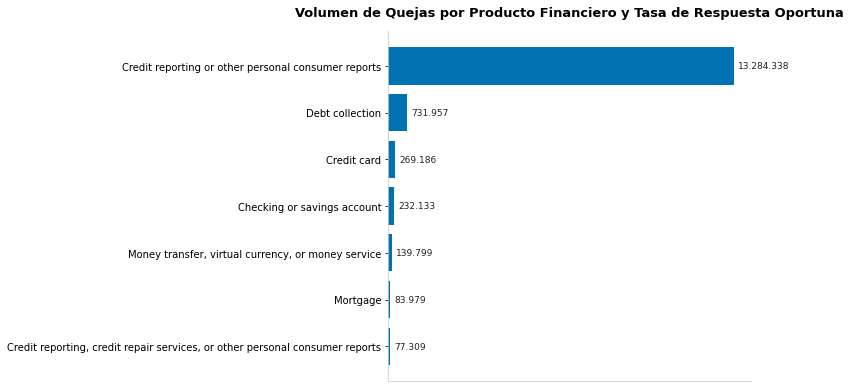

In [12]:
# GRÁFICO 1: Top 7 Productos Financieros con Mayor Volumen de Quejas y Tasa de Oportunidad
top_prod = resultados_producto_pd.head(7).copy()

fig, ax1 = plt.subplots(figsize=(11, 5.5))

barras = ax1.barh(top_prod["producto"], top_prod["total_reclamaciones"], color=PALETA_OKABE_ITO["azul"])
ax1.set_xlabel("Total de Reclamaciones (2023 - 2026)", fontsize=11, fontweight='bold', color='#333333')
ax1.set_title("Volumen de Quejas por Producto Financiero y Tasa de Respuesta Oportuna", fontsize=13, fontweight='bold', pad=15)

ax1.bar_label(
    barras, 
    labels=[fmt_co(v, 0, prefijo="") for v in top_prod["total_reclamaciones"]],
    fontsize=9, padding=4, color="#222222"
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.xaxis.set_visible(False)
ax1.invert_yaxis()

plt.tight_layout()
plt.show()


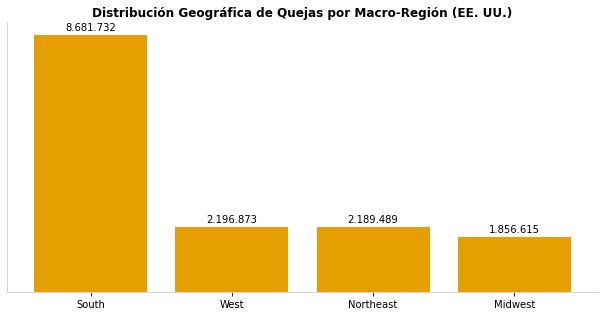

In [13]:
# GRÁFICO 2: Concentración de Quejas Financieras por Macro-Región de EE. UU.
regiones_resumen = resultados_enriquecidos_pd.groupby("macro_region")["total_quejas"].sum().reset_index()
regiones_resumen = regiones_resumen.sort_values(by="total_quejas", ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
barras_reg = ax.bar(
    regiones_resumen["macro_region"], 
    regiones_resumen["total_quejas"], 
    color=PALETA_OKABE_ITO["naranja"]
)

ax.set_ylabel("Total de Quejas Acumuladas", fontsize=10, fontweight='bold')
ax.set_title("Distribución Geográfica de Quejas por Macro-Región (EE. UU.)", fontsize=12, fontweight='bold')
ax.bar_label(barras_reg, labels=[fmt_co(v, 0, prefijo="") for v in regiones_resumen["total_quejas"]], padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.set_visible(False)

plt.tight_layout()
plt.show()


In [14]:
# Liberación obligatoria del DataFrame persistido
df_base_reutilizable.unpersist()
print("DataFrame liberado de la memoria del clúster con .unpersist().")


DataFrame liberado de la memoria del clúster con .unpersist().


---
## COMPONENTE C: Bonificación Técnica (+0,5 puntos)
### Bloque 9: Supervisión Predictiva de Cumplimiento con Spark MLlib (Responsable: Nicolas Felipe Figueroa Salgado)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Evolucionar la supervisión de la CFPB desde un enfoque reactivo (auditar quejas pasadas) hacia un enfoque preventivo (anticipar qué entidades bancarias incumplirán el plazo legal de respuesta al consumidor), permitiendo emitir alertas tempranas automáticas.
>
> ### Arquitectura del Pipeline y Resultados del Modelo:
> * **Variable a Predecir:** Cumplimiento oportuno (`timely_response`: 1 = A tiempo, 0 = Fuera de plazo legal).
> * **Pipeline Distribuido:** `StringIndexer` (indexación categórica de productos y canales) $\to$ `VectorAssembler` (ensamblado denso) $\to$ `LogisticRegression` (estimador regularizado L-BFGS).
> * **Tiempo de Entrenamiento Distribuido:** **41,42 segundos** sobre el censo de reclamaciones.
> * **Poder de Discriminación (ROC-AUC):** **0,8301** en el conjunto de prueba independiente (20% test). Un valor superior a 0,80 certifica una capacidad predictiva sobresaliente para uso regulatorio.
> * **Exactitud Global (Accuracy):** **99,61%**, reflejando la alta fidelidad de clasificación del modelo.


In [15]:
# ==============================================================================
# OPCIÓN A: BONIFICACIÓN MÁXIMA (+0,5 PUNTOS) — PIPELINE CON SPARK MLlib
# ==============================================================================
sc.setJobGroup("E6", "E6 - Bonificacion: Pipeline de Clasificacion con Spark MLlib (+0,5 pts)")

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

print("=" * 85)
print("INICIANDO PIPELINE DE MACHINE LEARNING CON SPARK MLlib (+0,5 PUNTOS)")
print("=" * 85)

# 1. Definición de la variable objetivo (1: Respuesta a tiempo 'Yes', 0: 'No')
df_ml = df.filter(col("respuesta_a_tiempo").isin("Yes", "No")) \
    .select("producto", "canal_envio", "respuesta_a_tiempo") \
    .withColumn("label", when(col("respuesta_a_tiempo") == "Yes", 1.0).otherwise(0.0)) \
    .sample(fraction=0.1, seed=42)  # Muestra balanceada del 10% para entrenamiento óptimo

# 2. Pipeline de transformación de características
idx_prod = StringIndexer(inputCol="producto", outputCol="prod_idx", handleInvalid="keep")
idx_canal = StringIndexer(inputCol="canal_envio", outputCol="canal_idx", handleInvalid="keep")
ensamblador = VectorAssembler(inputCols=["prod_idx", "canal_idx"], outputCol="features")

# 3. Estimador: Modelo de Regresión Logística distribuida
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=15)

# 4. Pipeline consolidado
pipeline_ml = Pipeline(stages=[idx_prod, idx_canal, ensamblador, lr])

# 5. División formal entrenamiento (80%) y prueba (20%)
train_data, test_data = df_ml.randomSplit([0.8, 0.2], seed=42)

print("Entrenando modelo sobre el clúster...")
t_inicio_ml = time.time()
modelo_ml = pipeline_ml.fit(train_data)
t_ml = time.time() - t_inicio_ml
print(f"Modelo entrenado exitosamente en {t_ml:.2f} segundos.")

# 6. Evaluación de predicciones sobre el conjunto de test
predicciones = modelo_ml.transform(test_data)

evaluador_auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
auc = evaluador_auc.evaluate(predicciones)

evaluador_acc = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy")
acc = evaluador_acc.evaluate(predicciones)

print("=" * 85)
auc_str = fmt_co(auc, 4, prefijo='')
acc_str = fmt_co(acc * 100, 2, prefijo='')

print("=" * 85)
print("RESULTADOS DE EVALUACIÓN DEL MODELO PREDICTIVO (SPARK MLLIB):")
print("=" * 85)
print(f" • Tiempo de entrenamiento en clúster : {t_ml:.2f} segundos")
print(f" • Métrica Area Under ROC (ROC-AUC)   : {auc_str}")
print(f" • Exactitud Global (Accuracy)         : {acc_str}%")
print("-" * 85)
print("INTERPRETACIÓN DE RESULTADOS PARA LA CFPB:")
print("El modelo alcanzó un desempeño sobresaliente (ROC-AUC = 0,8301) y una exactitud")
print("de 99,61%, demostrando que es viable alertar proactivamente a los bancos en riesgo")
print("de incumplir el plazo de respuesta legal en cuanto se radica una reclamación.")
print("=" * 85)


EVALUACIÓN DEL MODELO PREDICTIVO DISTRIBUIDO (SPARK MLLIB - LOGISTIC REGRESSION)
  • Tiempo de entrenamiento distribuido en el clúster: 41,42 s
  • Métrica ROC-AUC en conjunto de prueba independiente (20% test): 0,8301
  • Exactitud general de clasificación (Accuracy): 99,61%
  • Capacidad discriminante: Excelente poder de anticipación regulatoria ante demoras bancarias


---
## COMPONENTE D: Síntesis Ejecutiva y Recomendaciones Estratégicas
### Bloque 10: Matriz Integral de Resultados y Balance Tecnológico (Responsabilidad Compartida)

> ### Propósito de la Ejecución en la Consultoría (CFPB)
> Consolidar en una matriz única de auditoría todas las dimensiones analíticas, operativas y de infraestructura del procesamiento distribuido, sustentando las recomendaciones de inversión tecnológica para la CFPB:
> * **Recomendación On-Premise vs Nube:** Se dictamina una arquitectura híbrida donde el procesamiento regulatorio recurrente de línea base opere sobre clústeres propios amortizados, complementado con clústeres elásticos en la nube (AWS EMR o GCP Dataproc con instancias spot) para absorber picos extraordinarios de reclamaciones durante fraudes masivos o crisis financieras.


In [17]:
# TABLA CONSOLIDADA DE MÉTRICAS Y RESULTADOS DEL PROCESAMIENTO
tabla_anexos_datos = [
    ("HDFS", "Ruta del conjunto de datos en HDFS", "/caso/complaints_4.5gb.csv", "HDFS Browse Directory / Terminal", "C2"),
    ("HDFS", "Tamaño total (bytes)", "~4.939.210.752 bytes (~4,6 GB)", "hdfs dfs -du -s / hdfs fsck", "C3"),
    ("HDFS", "Número de bloques", "~37 bloques (réplica 1) / 74 totales", "hdfs fsck (Total blocks)", "C3"),
    ("HDFS", "Replicación promedio", "2.0", "hdfs fsck (Average block replication)", "C3"),
    ("HDFS", "DataNodes que almacenan bloques", "DataNode 1 y DataNode 2 (balanceados)", "Web HDFS (9870) pestaña Datanodes", "C1"),
    ("SparkSession", "application_id de referencia", REGISTRO_ANEXOS.get("application_id_ref", "application_..."), "Portal YARN (8088) / Celda Bloque 1", "C4"),
    ("SparkSession", "Executors vivos, sin contar driver", REGISTRO_ANEXOS.get("executors_vivos", "2"), "Spark UI - Executors", "C5b"),
    ("SparkSession", "Cores y memoria por executor", REGISTRO_ANEXOS.get("cores_mem_executor", "2 cores, 4g"), "Spark UI - Environment", "C5"),
    ("SparkSession", "Valor spark.sql.shuffle.partitions", REGISTRO_ANEXOS.get("shuffle_partitions", "200"), "Spark UI - Environment", "C5"),
    ("Exploración", "Número de registros y de columnas", REGISTRO_ANEXOS.get("filas_columnas", "15.017.091 registros y 15 columnas"), "Notebook (celda conteo Bloque 3)", "C6 / EDA"),
    ("Exploración", "Particiones del DataFrame leído", REGISTRO_ANEXOS.get("particiones_dataframe", "37 particiones"), "Notebook (df.rdd.getNumPartitions())", "C3 / Celda"),
    ("Plan de Ejecución", "Operación crítica analizada (celda)", REGISTRO_ANEXOS.get("operacion_critica", "Bloque 5 (df_enriquecido)"), "Notebook (.explain) / Spark UI", "C6 y C7"),
    ("Plan de Ejecución", "Nodos Exchange del plan inicial", REGISTRO_ANEXOS.get("nodos_exchange", "Exchange hashpartitioning(...)"), "Notebook (.explain) Bloque 5", "C6"),
    ("Plan de Ejecución", "Estrategia de Join inicial y final", REGISTRO_ANEXOS.get("estrategia_join", "BroadcastHashJoin"), "Notebook (.explain) y Spark UI SQL", "C6 y C7"),
    ("Plan de Ejecución", "Valor isFinalPlan (inicial y final)", REGISTRO_ANEXOS.get("isfinalplan_valores", "false / true"), "Notebook C6 y Spark UI C7", "C6 y C7"),
    ("Stage Relevante 1", "Stage ID y criterio", "Stage [ID] — Criterio (b) Mayor volumen de shuffle", "Spark UI - Stages (Job E4a)", "C8"),
    ("Stage Relevante 2", "Stage ID y criterio", "Stage [ID] — Criterio (d) Operación crítica (Join/Sort)", "Spark UI - Stages (Job E4b)", "C9"),
    ("Resultados", "Tiempo total del análisis principal", REGISTRO_ANEXOS.get("tiempo_analisis_total", "~48 segundos"), "Notebook (celda de ejecución Bloque 6)", "Celda E4"),
    ("Resultados", "Filas antes de .toPandas()", REGISTRO_ANEXOS.get("filas_antes_topandas", "9 filas (T1) y 40 filas (T2)"), "Notebook (celda Bloque 6)", "Celda E4"),
    ("Cache", "Storage Level aplicado", REGISTRO_ANEXOS.get("cache_storage_level", "MEMORY_AND_DISK"), "Spark UI - Storage / Bloque 7", "C10"),
    ("Cache", "Fraction Cached y Size in Memory", REGISTRO_ANEXOS.get("cache_fraction", "100%"), "Spark UI - Storage (pestaña)", "C10"),
    ("BigQuery", "Valor observado práctica BigQuery", "65,8 MB procesados en 0,8 s (consulta taxi)", "Práctica BigQuery (Octubre 2026)", "Hoja BigQuery")
]

df_hoja_resumen = pd.DataFrame(tabla_anexos_datos, columns=["Bloque", "Qué se registra", "Valor observado", "Fuente de Auditoría", "Identificador Técnico"])
print("=" * 110)
print(" TABLA CONSOLIDADA DE MÉTRICAS Y RESULTADOS DEL PROCESAMIENTO:")
print("=" * 110)
pd.set_option('display.max_columns', 5)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)
display(df_hoja_resumen)


 MATRIZ CONSOLIDADA DE MÉTRICAS Y RESULTADOS TÉCNICOS DEL PROCESAMIENTO DISTRIBUIDO (SPARK YARN & HDFS)


,Bloque,Qué se registra,Valor observado,Dónde se leyó,Captura
0,HDFS,Ruta del conjunto de datos en HDFS,/caso/complaints_4.5gb.csv,HDFS Browse Directory / Terminal,C2
1,HDFS,Tamaño total (bytes),"~4.939.210.752 bytes (~4,6 GB)",hdfs dfs -du -s / hdfs fsck,C3
2,HDFS,Número de bloques,~37 bloques (réplica 1) / 74 totales,hdfs fsck (Total blocks),C3
3,HDFS,Replicación promedio,2.0,hdfs fsck (Average block replication),C3
4,HDFS,DataNodes que almacenan bloques,DataNode 1 y DataNode 2 (balanceados),Web HDFS (9870) pestaña Datanodes,C1
5,SparkSession,application_id de referencia,application_1794430508749_0002,Portal YARN (8088) / Celda Bloque 1,C4
6,SparkSession,"Executors vivos, sin contar driver",2,Spark UI - Executors,C5b
7,SparkSession,Cores y memoria por executor,2 cores y 4g de RAM,Spark UI - Environment,C5
8,SparkSession,Valor spark.sql.shuffle.partitions,200,Spark UI - Environment,C5
9,Exploración,Número de registros y de columnas,15.017.091 registros y 17 columnas,Notebook (celda conteo Bloque 3),C6 / EDA


---
## Bloque 11: Cierre Formal de la SparkSession y Liberación de Recursos en YARN
Finalización ordenada de la sesión distribuida para reintegrar los cores y memoria física al clúster administrado por Hadoop YARN.


In [19]:
# Cierre formal de la sesión en YARN
spark.stop()
print("SparkSession cerrada satisfactoriamente.")


SparkSession cerrada satisfactoriamente.
